# Core vs MTG LI over Western Sahel JJAS

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

In [2]:
base = "/gws/ssde/j25b/swift/mendrika/asnie/database/parquet"

core_thresholds = [79.53, 80.744, 82.64]   # 90, 95, 98
li_thresholds = [1.056, 2.617, 7.062]      # 90, 95, 98

cores = {}
lis = {}

# load cores
for thr in core_thresholds:

    tag = f"thr_{thr}".replace(".", "p")

    cores[thr] = pd.read_parquet(
        f"{base}/core_2025_{tag}.parquet"
    )

# load lightning
for thr in li_thresholds:

    tag = f"thr_{thr}".replace(".", "p")

    lis[thr] = pd.read_parquet(
        f"{base}/li_2025_{tag}.parquet"
    )

In [3]:
labels = {79.53:90, 80.744:95, 82.64:98,
          1.056:90, 2.617:95, 7.062:98}

for thr in core_thresholds:
    p = labels[thr]
    print(f"core p{p}:", cores[thr]["time"].min(), cores[thr]["time"].max())

for thr in li_thresholds:
    p = labels[thr]
    print(f"li p{p}:", lis[thr]["time"].min(), lis[thr]["time"].max())

core p90: 2025-06-01 00:00:00 2025-08-31 08:00:00
core p95: 2025-06-01 00:00:00 2025-08-31 08:00:00
core p98: 2025-06-01 00:30:00 2025-08-30 23:45:00
li p90: 2025-06-01 00:15:00 2025-09-30 23:45:00
li p95: 2025-06-01 00:15:00 2025-09-30 23:45:00
li p98: 2025-06-01 00:15:00 2025-09-30 23:45:00


In [4]:
# shift core times to match 15-minute LI accumulation
for thr in core_thresholds:
    cores[thr]["time_li"] = cores[thr]["time"] + pd.Timedelta(minutes=15)

cores_aligned = {}
lis_aligned = {}

for cthr, lthr in zip(core_thresholds, li_thresholds):

    core_times = set(cores[cthr]["time_li"])
    li_times = set(lis[lthr]["time"])

    common_times = core_times.intersection(li_times)

    cores_aligned[(cthr, lthr)] = cores[cthr][
        cores[cthr]["time_li"].isin(common_times)
    ].copy()

    lis_aligned[(cthr, lthr)] = lis[lthr][
        lis[lthr]["time"].isin(common_times)
    ].copy()

    print(
        f"core p{cthr} vs li p{lthr}:",
        len(common_times),
        "timesteps",
        "| cores:", len(cores_aligned[(cthr, lthr)]),
        "| li:", len(lis_aligned[(cthr, lthr)])
    )

core p79.53 vs li p1.056: 2690 timesteps | cores: 7823 | li: 67396
core p80.744 vs li p2.617: 2016 timesteps | cores: 5249 | li: 33963
core p82.64 vs li p7.062: 1138 timesteps | cores: 2270 | li: 13817


In [5]:
def latlon_to_xy_km(lat, lon):
    """
    Convert latitude and longitude coordinates to approximate Cartesian
    coordinates in kilometres.

    This function applies a simple equirectangular projection to transform
    geographic coordinates (lat, lon) into planar (x, y) coordinates. The
    conversion is suitable for computing Euclidean distances between nearby
    points (e.g., storm-object centroids) over a limited geographic region.

    Longitude distances are scaled by cos(mean latitude) to account for the
    decrease in east–west distance away from the equator.

    Parameters
    ----------
    lat : array-like
        Latitudes in degrees.
    lon : array-like
        Longitudes in degrees.

    Returns
    -------
    xy : ndarray of shape (N, 2)
        Array containing projected coordinates in kilometres, where each row
        corresponds to a point (x, y).
    """

    R = 6371.0

    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)

    x = R * lon_rad * np.cos(np.mean(lat_rad))                      # mean to make sure it's consistent across dataset (assuming a single reference latitude for simplicity)
    y = R * lat_rad

    return np.column_stack((x, y))

In [6]:
def core_to_li_distances(df_core, df_li, start_hour=12, end_hour=21):

    matches = []

    # Optional restriction to convective hours
    if start_hour is not None and end_hour is not None:

        core_active = df_core[
            (df_core["hour"] >= start_hour) &
            (df_core["hour"] <= end_hour)
        ]

        li_active = df_li[
            (df_li["hour"] >= start_hour) &
            (df_li["hour"] <= end_hour)
        ]

    else:

        core_active = df_core
        li_active = df_li

    # group lightning once
    li_groups = {t: g for t, g in li_active.groupby("time")}

    for t, core_group in core_active.groupby("time_li"):

        li_group = li_groups.get(t)

        if li_group is None or len(core_group) == 0:
            continue

        li_xy = latlon_to_xy_km(
            li_group["lat_centroid"].values,
            li_group["lon_centroid"].values
        )

        tree = cKDTree(li_xy)

        core_xy = latlon_to_xy_km(
            core_group["lat_centroid"].values,
            core_group["lon_centroid"].values
        )

        distances, _ = tree.query(core_xy, k=1)

        matches.extend(distances)

    return np.array(matches)

In [7]:
distances = {}

for cthr, lthr in zip(core_thresholds, li_thresholds):

    core_df = cores_aligned[(cthr, lthr)]
    li_df = lis_aligned[(cthr, lthr)]

    distances[lthr] = core_to_li_distances(
        core_df,
        li_df
    )

    print(
        f"core {cthr} vs li {lthr}:",
        len(distances[lthr]),
        "matches"
    )

core 79.53 vs li 1.056: 4543 matches
core 80.744 vs li 2.617: 3054 matches
core 82.64 vs li 7.062: 1273 matches


Strong lightning activity is typically colocated with convective cores.

Increasing lightning intensity thresholds progressively concentrates lightning activity near convective cores, indicating that the strongest electrical activity is closely associated with deep convective structures.

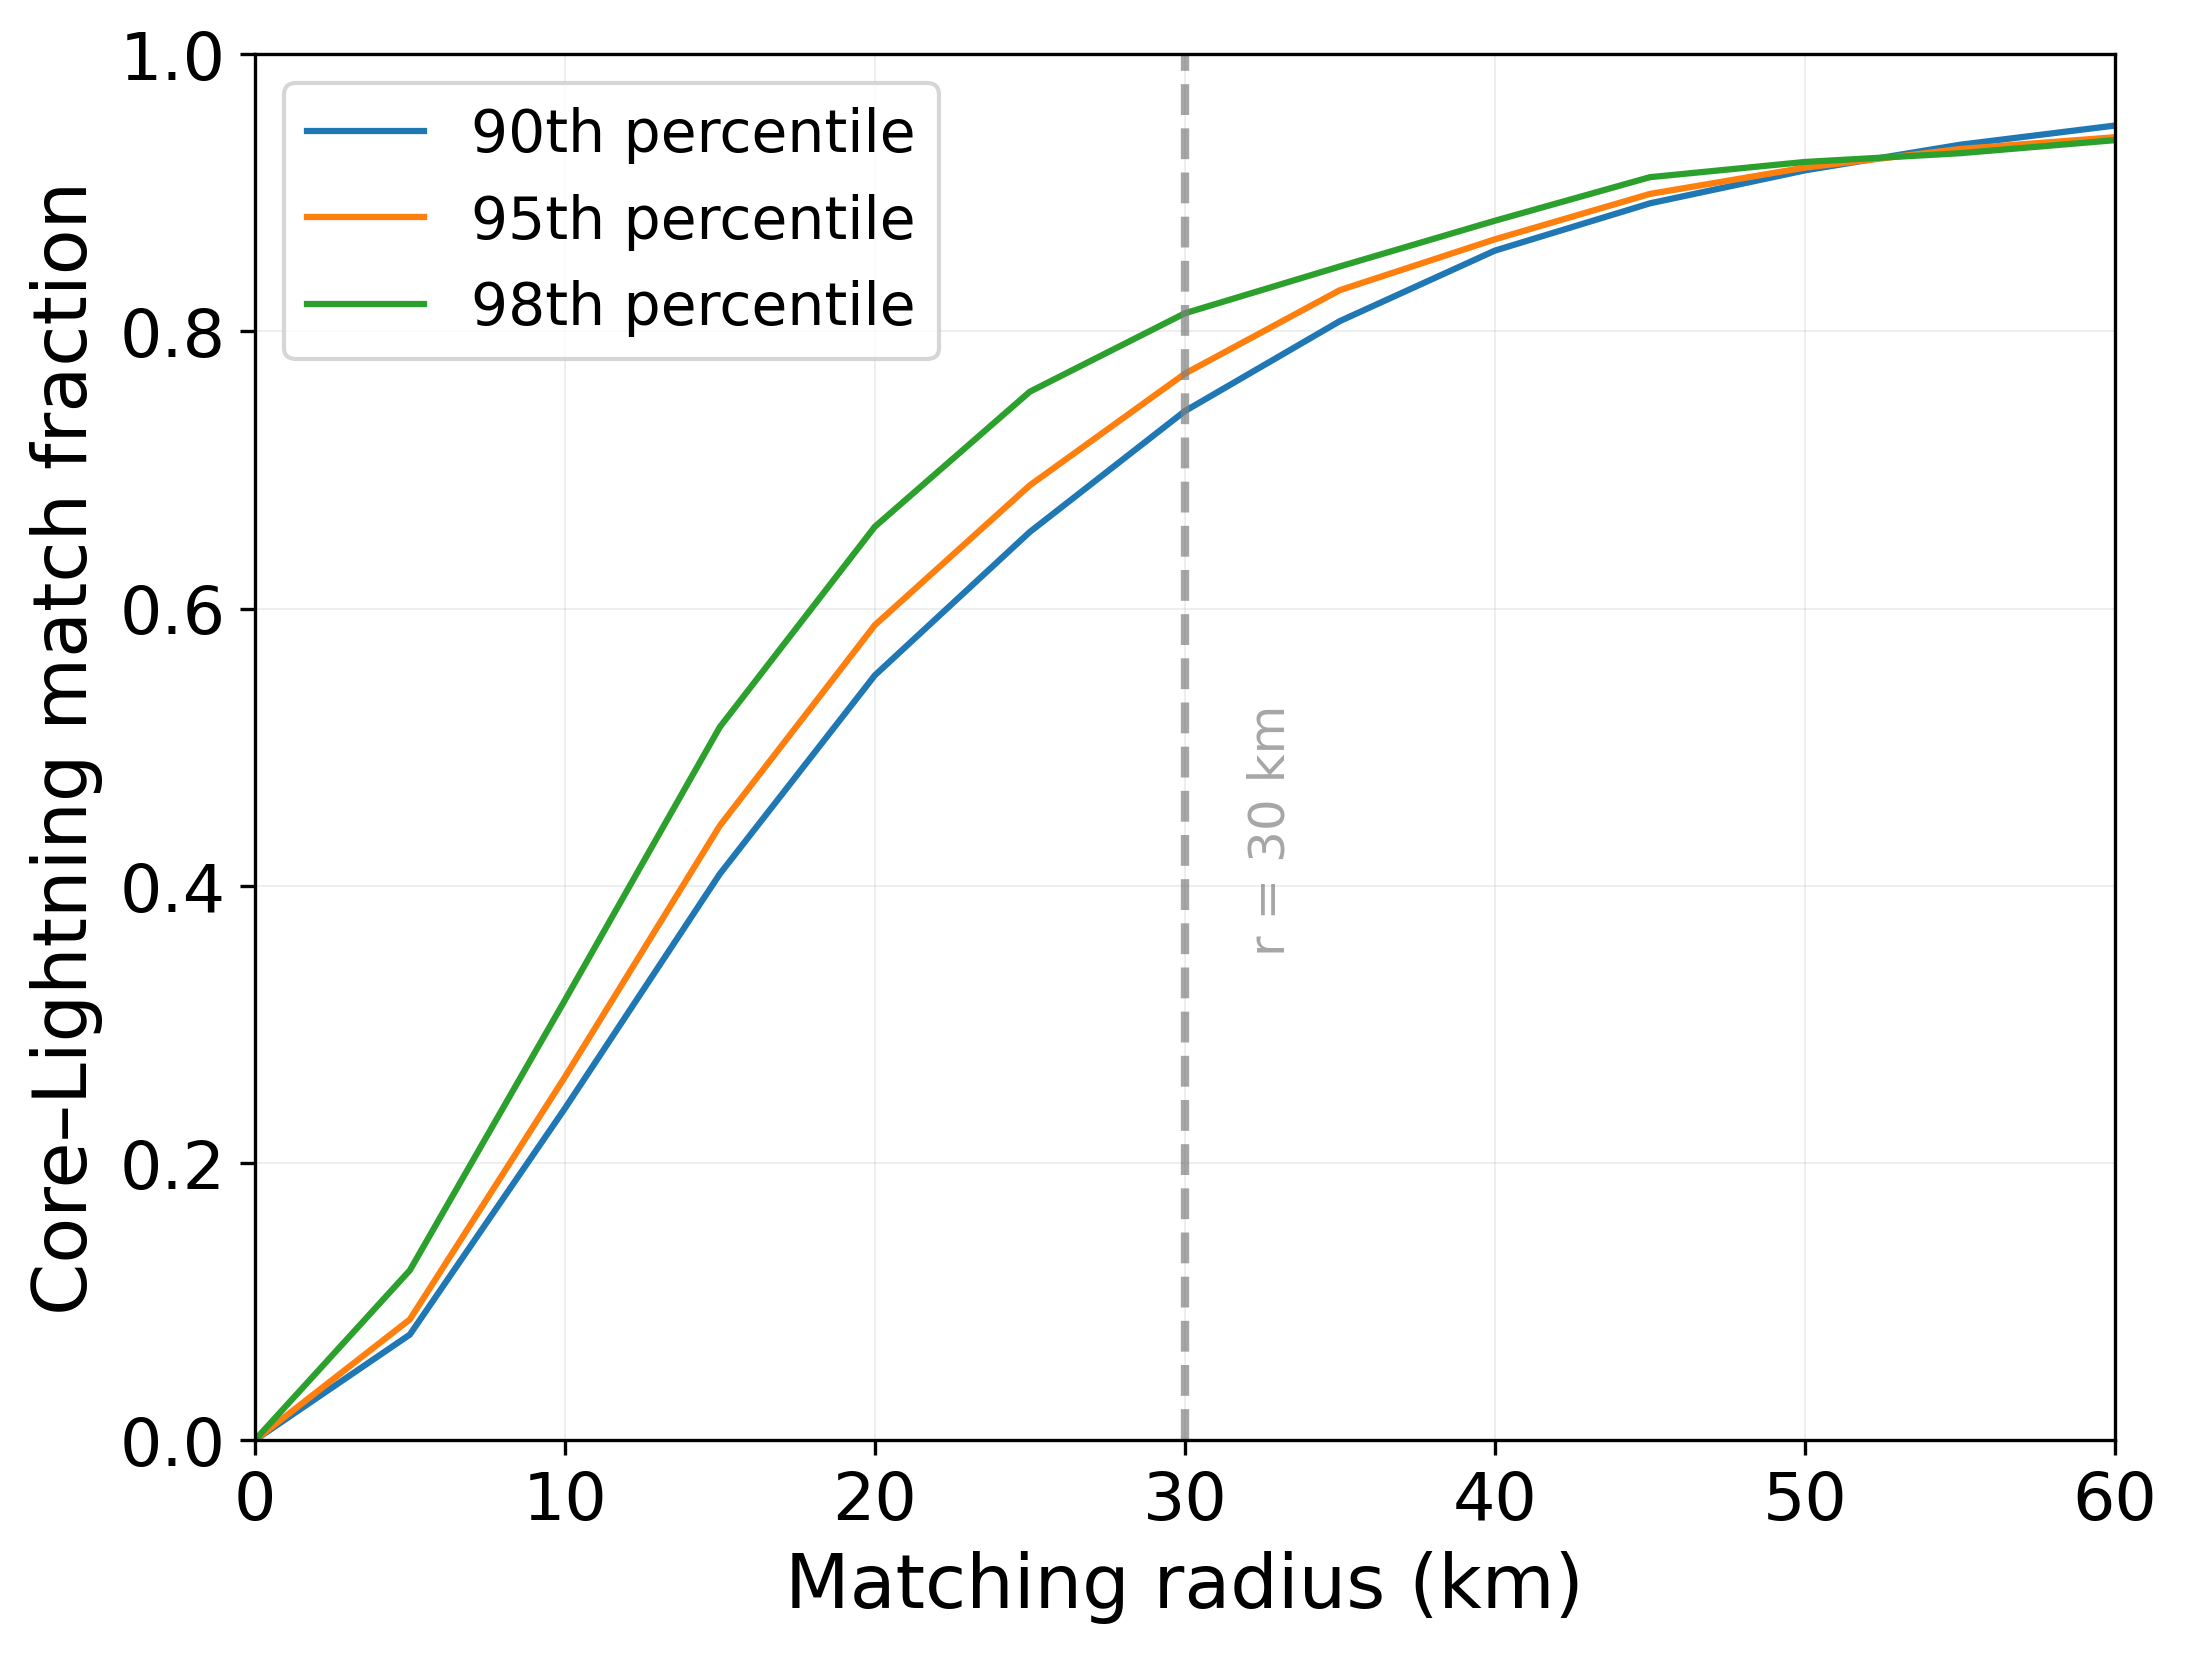

In [8]:
radii = np.arange(0, 105, 5)

rates = {}

for thr, d in distances.items():
    rates[thr] = [np.mean(d <= r) for r in radii]

labels = {
    1.056: "90th percentile",
    2.617: "95th percentile",
    7.062: "98th percentile"
}

plt.figure(figsize=(8, 6), dpi=300)

for thr in distances:
    plt.plot(radii, rates[thr], label=labels[thr])

plt.axvline(
    30,
    color="grey",
    linestyle="--",
    linewidth=2,
    alpha=0.7
)

plt.text(
    32,
    0.35,
    "r = 30 km",
    fontsize=12,
    color="grey",
    rotation=90,
    va="bottom",
    alpha=0.7
)

plt.xlabel("Matching radius (km)", fontsize=18)
plt.ylabel("Core–Lightning match fraction", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlim(0, 60)
plt.ylim(0, 1.0)

plt.grid(True, linewidth=0.1)

plt.show()

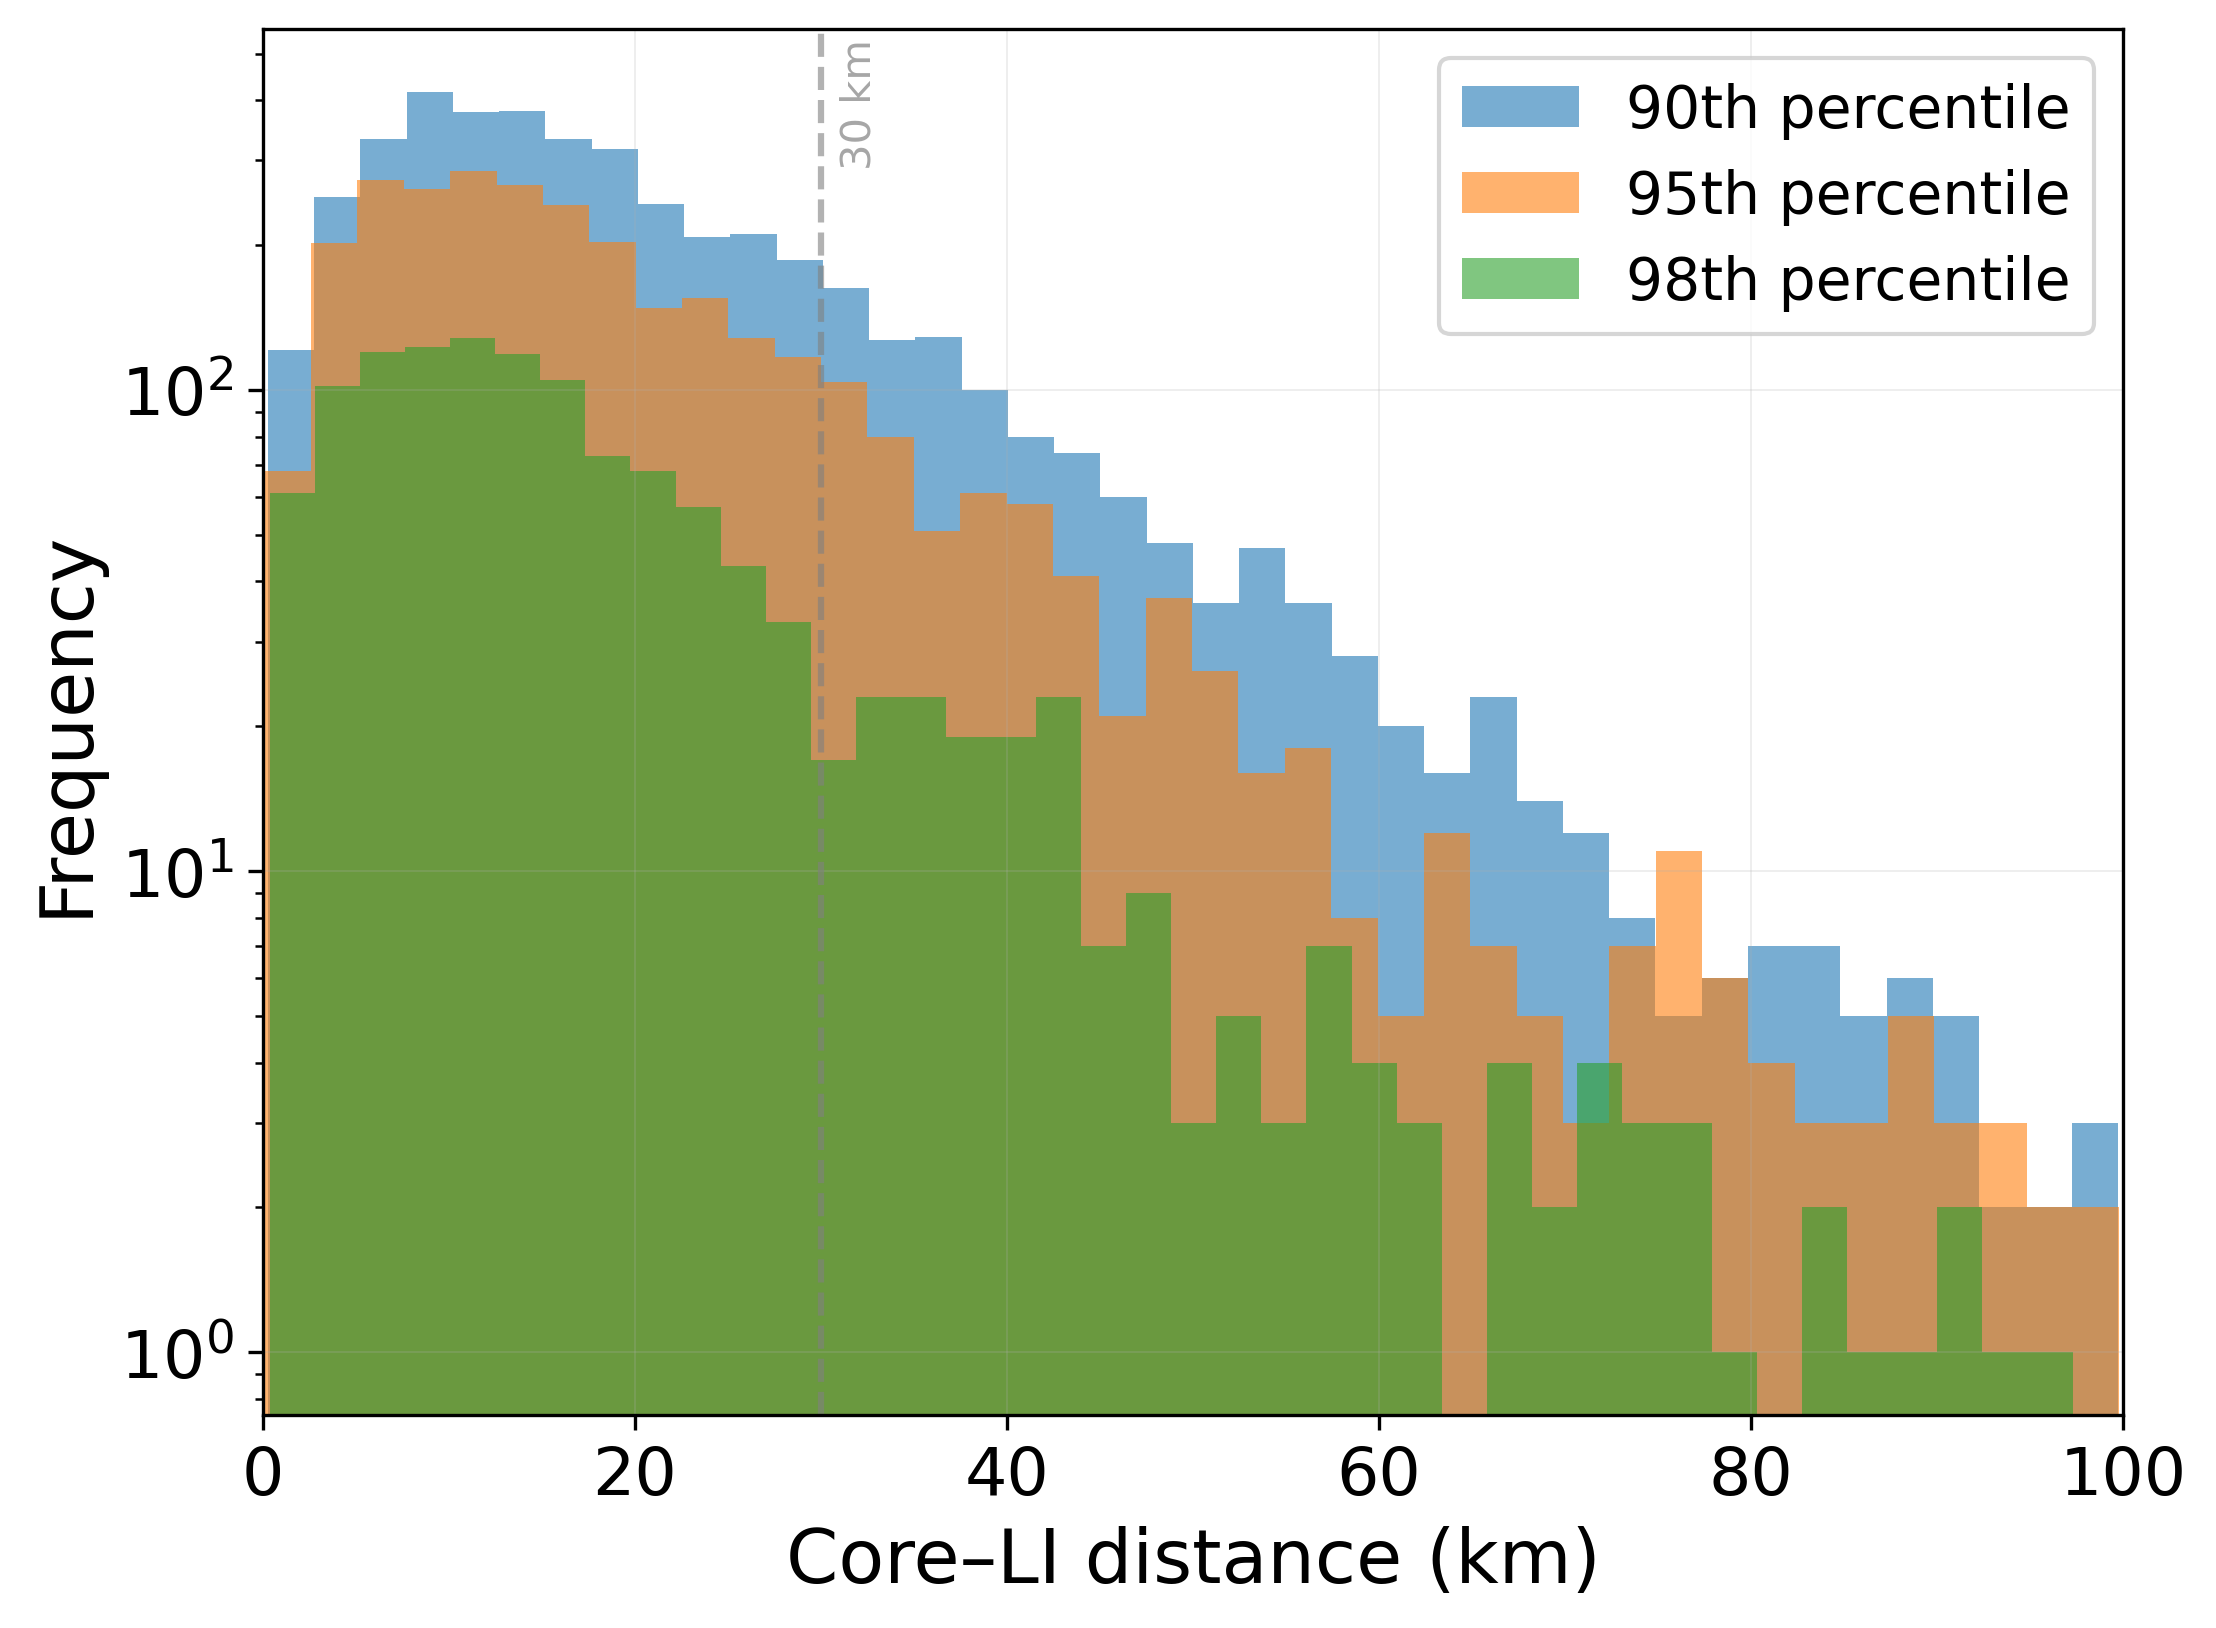

In [9]:
plt.figure(figsize=(8, 6), dpi=300)

for thr, d in distances.items():

    d_clip = d[d <= 100]

    plt.hist(
        d_clip,
        bins=40,
        alpha=0.6,
        label=labels[thr]
    )

plt.yscale("log")

plt.xlabel("Core–LI distance (km)", fontsize=18)
plt.ylabel("Frequency", fontsize=18)
plt.axvline(30, color="grey", linestyle="--", alpha=0.6)
plt.text(
    31,
    300,
    "30 km",
    rotation=90,
    color="grey",
    alpha=0.7
)


plt.xlim(0,100)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.grid(True, linewidth=0.1)

plt.show()

- Stronger convective cores tend to have lightning closer to the core centre.
- Meaning lightning is usually slightly displaced from the core centroid, which is expected physically.

1️⃣ Convective cores are strongly associated with lightning.

2️⃣ Typical separation is ~10–20 km.

3️⃣ The effective association radius is ~30–50 km.


Detected cores correspond to real deep convection, because lightning is tightly colocated.